<a href="https://colab.research.google.com/github/Charanca24/Team-E/blob/main/flu_vaccine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Flu Vaccine Cost Challenge – Dataset A
# Goal: decide who to send a seasonal flu vaccine to, so the town's total expected cost (vaccines + hospitalisations) is as low as possible.

In [3]:
REPO_URL = "https://github.com/Charanca24/Team-E.git"
DATA_DIR = "Team-E"
!git clone {REPO_URL}

Cloning into 'Team-E'...
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), 190.82 KiB | 4.34 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.calibration import calibration_curve

SEED = 42
train = pd.read_csv(f"{DATA_DIR}/dataset_A_training (1).csv", index_col="respondent_id")
test  = pd.read_csv(f"{DATA_DIR}/dataset_A_testing.csv",     index_col="respondent_id")
TARGET = "seasonal_vaccine"
X, y = train.drop(columns=TARGET), train[TARGET]
print("train:", X.shape, " test:", test.shape)

train: (4756, 29)  test: (4749, 29)


## 2. Exploratory Data Analysis

seasonal_vaccine
1    0.536
0    0.464
Name: proportion, dtype: float64


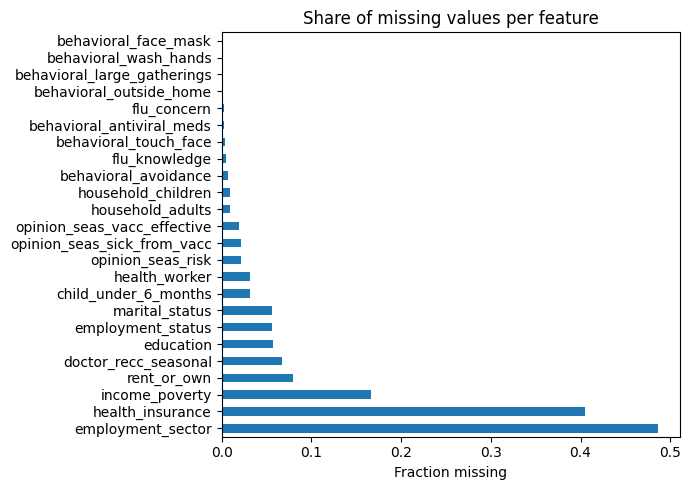

In [6]:
# Target balance: ~54% accept the vaccine, so classes are roughly balanced
print(y.value_counts(normalize=True).round(3))

# Missing values per feature
miss = X.isna().mean().sort_values(ascending=False)
miss[miss > 0].plot(kind="barh", figsize=(7, 5), title="Share of missing values per feature")
plt.xlabel("Fraction missing"); plt.tight_layout(); plt.show()

**Observation:** employment_sector (~49%) and health_insurance (~40%) are heavily missing. Instead of dropping them, we impute with a "missing" category/indicator, because not answering may itself be predictive.

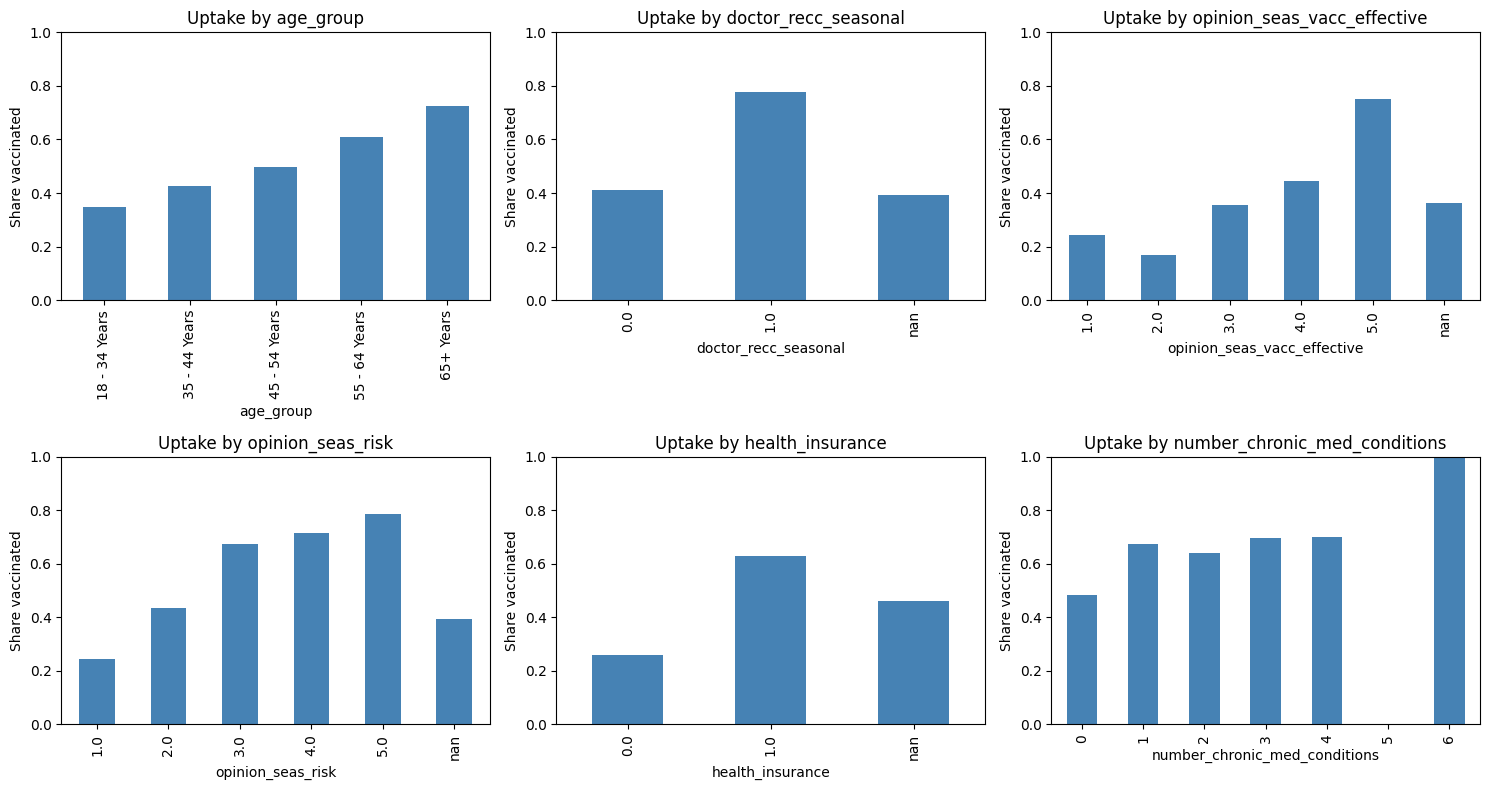

In [7]:
key_cols = ["age_group", "doctor_recc_seasonal", "opinion_seas_vacc_effective",
            "opinion_seas_risk", "health_insurance", "number_chronic_med_conditions"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_cols):
    train.groupby(col, dropna=False)[TARGET].mean().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Uptake by {col}"); ax.set_ylabel("Share vaccinated"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Observation:** uptake rises steeply with age (35% for 18–34 vs 73% for 65+), and with doctor recommendation, belief that the vaccine works, and perceived risk.

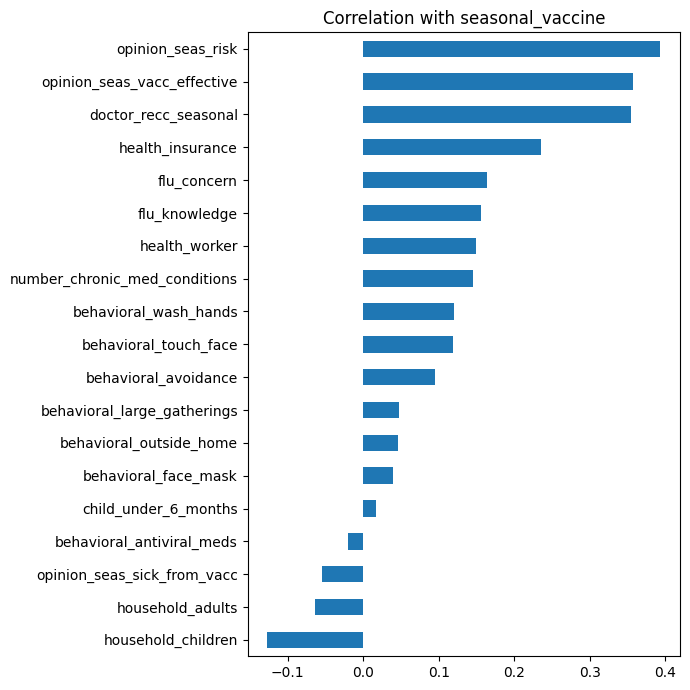

In [8]:
num = train.select_dtypes("number")
num.corr()[TARGET].drop(TARGET).sort_values().plot(kind="barh", figsize=(7, 7),
                                                   title="Correlation with seasonal_vaccine")
plt.tight_layout(); plt.show()

## 3. Task-specific metric: expected total cost
Vaccine = $300, hospitalisation = $18,500, everyone gets infected.

| Decision | Wants vaccine | Refuses |
|---|---|---|
| Send | 300 + p(1−VE)·18500 | 300 + p·18500 |
| Don't send | 300 + p·18500 | p·18500 |

p = hospitalisation probability if unvaccinated, VE = vaccine effectiveness.
Sending to an accepter saves p·VE·18500; sending to a refuser wastes $300.
With q = predicted probability of accepting, we send when: q·p·VE·18500 > (1−q)·300

p by age from CDC 2017–18 (H3N2 season): 18–49 ≈ 0.56%, 50–64 ≈ 1.06%, 65+ ≈ 9.1%. Each chronic condition is assumed to double the risk. VE = 0.35.

In [9]:
VACCINE_COST, HOSP_COST = 300, 18_500
VE = 0.35
P_HOSP_AGE = {"18 - 34 Years": 0.0056, "35 - 44 Years": 0.0056, "45 - 54 Years": 0.0080,
              "55 - 64 Years": 0.0106, "65+ Years": 0.0910}
CHRONIC_RR = 1.0   # extra relative risk per chronic condition

def hosp_prob(df, chronic_rr=CHRONIC_RR):
    """Probability of hospitalisation if infected & unvaccinated, per person."""
    base = df["age_group"].map(P_HOSP_AGE).astype(float)
    n_chronic = df["number_chronic_med_conditions"].fillna(0).clip(upper=3)
    return np.clip(base * (1 + chronic_rr * n_chronic), 0, 1)

def total_cost(send, accepts, p, ve=VE):
    """Expected total cost to the town for a send/don't-send decision."""
    send, accepts = np.asarray(send, bool), np.asarray(accepts, bool)
    unprotected = p * HOSP_COST
    cost = np.where(send & accepts,  VACCINE_COST + p * (1 - ve) * HOSP_COST,
           np.where(send & ~accepts, VACCINE_COST + unprotected,
           np.where(~send & accepts, VACCINE_COST + unprotected,
                                     unprotected)))
    return cost.sum()

def decide(q, p, ve=VE):
    """Send a vaccine when the expected saving beats the expected waste."""
    return q * p * ve * HOSP_COST > (1 - q) * VACCINE_COST

p_train = hosp_prob(X).values
p_test  = hosp_prob(test).values
print("Hospitalisation probabilities computed for", len(p_train), "train and", len(p_test), "test people")

Hospitalisation probabilities computed for 4756 train and 4749 test people


In [10]:
yb = y.values.astype(bool)
baselines = {
    "Send to nobody":    total_cost(np.zeros_like(yb), yb, p_train),
    "Send to everyone":  total_cost(np.ones_like(yb),  yb, p_train),
    "Perfect knowledge": total_cost(yb, yb, p_train),
}
for k, v in baselines.items():
    print(f"{k:20s} ${v:,.0f}  (${v/len(y):.0f} per person)")

Send to nobody       $4,493,057  ($945 per person)
Send to everyone     $4,237,937  ($891 per person)
Perfect knowledge    $3,576,437  ($752 per person)


## 4. Pre-processing
Ordinal encoding for age, education and income (natural order); one-hot for other categories with a "missing" level; median imputation + missing indicators for numeric answers.

In [11]:
ordinal_cols = ["age_group", "education", "income_poverty"]
ordinal_cats = [["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"],
                ["< 12 Years", "12 Years", "Some College", "College Graduate"],
                ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"]]
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c]) and c not in ordinal_cols]
num_cols = [c for c in X.columns if c not in cat_cols + ordinal_cols]

def make_preprocessor(scale=True):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))]
    if scale: num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("ord", Pipeline([("enc", OrdinalEncoder(categories=ordinal_cats,
                                                 handle_unknown="use_encoded_value", unknown_value=np.nan)),
                          ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler() if scale else "passthrough")]), ordinal_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])
print("numeric:", len(num_cols), "| ordinal:", ordinal_cols, "| one-hot:", cat_cols)

numeric: 19 | ordinal: ['age_group', 'education', 'income_poverty'] | one-hot: ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


## 5. Models, cross-validation & tuning
We tune on log-loss (not accuracy) because the decision rule needs well-calibrated probabilities.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "LogReg": (Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=2000))]),
               {"clf__C": [0.01, 0.1, 1.0]}),
    "RandomForest": (Pipeline([("prep", make_preprocessor(scale=False)),
                               ("clf", RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1))]),
                     {"clf__min_samples_leaf": [3, 10], "clf__max_features": ["sqrt", 0.3]}),
    "HistGB": (Pipeline([("prep", make_preprocessor(scale=False)),
                         ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
               {"clf__learning_rate": [0.03, 0.08], "clf__max_depth": [3, None],
                "clf__max_iter": [200], "clf__l2_regularization": [0.0, 1.0]}),
}

best_models, oof = {}, {}
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="neg_log_loss", n_jobs=-1).fit(X, y)
    best_models[name] = gs.best_estimator_
    # out-of-fold probabilities = honest predictions on unseen data
    oof[name] = cross_val_predict(gs.best_estimator_, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:13s} best={gs.best_params_}  logloss={-gs.best_score_:.4f}  AUC={roc_auc_score(y, oof[name]):.4f}")

LogReg        best={'clf__C': 0.1}  logloss=0.4890  AUC=0.8470
RandomForest  best={'clf__max_features': 0.3, 'clf__min_samples_leaf': 3}  logloss=0.4898  AUC=0.8445
HistGB        best={'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.08, 'clf__max_depth': 3, 'clf__max_iter': 200}  logloss=0.4780  AUC=0.8524


Ensemble AUC=0.8540  logloss=0.4757


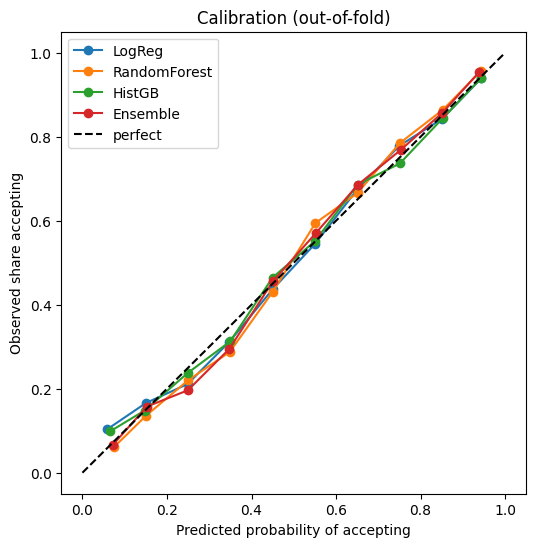

In [13]:
oof["Ensemble"] = np.mean([oof[m] for m in ["LogReg", "RandomForest", "HistGB"]], axis=0)
print(f"Ensemble AUC={roc_auc_score(y, oof['Ensemble']):.4f}  logloss={log_loss(y, oof['Ensemble']):.4f}")

plt.figure(figsize=(6, 6))
for name, q in oof.items():
    frac, mean_pred = calibration_curve(y, q, n_bins=10)
    plt.plot(mean_pred, frac, marker="o", label=name)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("Predicted probability of accepting"); plt.ylabel("Observed share accepting")
plt.title("Calibration (out-of-fold)"); plt.legend(); plt.show()

## 6. Cost evaluation: cost-aware rule vs 0.5 threshold (5-fold CV)

In [14]:
def fold_costs(q, rule):
    out = []
    for _, val_idx in cv.split(X, y):
        send = rule(q[val_idx], p_train[val_idx])
        out.append(total_cost(send, yb[val_idx], p_train[val_idx]) / len(val_idx))
    return np.array(out)

rules = {"cost-aware": decide, "0.5 threshold": lambda q, p: q > 0.5}
rows = []
for name, q in oof.items():
    for rname, rule in rules.items():
        c = fold_costs(q, rule)
        rows.append({"model": name, "rule": rname, "cost_per_person": c.mean(),
                     "std_across_folds": c.std(), "vaccines_sent": int(rule(q, p_train).sum())})
results = pd.DataFrame(rows).sort_values("cost_per_person").reset_index(drop=True)
results.round(2)

,model,rule,cost_per_person,std_across_folds,vaccines_sent
0,HistGB,cost-aware,788.04,36.21,1861
1,Ensemble,cost-aware,789.02,36.33,1803
2,RandomForest,cost-aware,790.21,36.04,1748
3,LogReg,cost-aware,790.72,36.86,1792
4,HistGB,0.5 threshold,804.41,34.34,2590
5,Ensemble,0.5 threshold,806.09,35.17,2595
6,LogReg,0.5 threshold,807.92,37.29,2588
7,RandomForest,0.5 threshold,808.45,34.27,2588


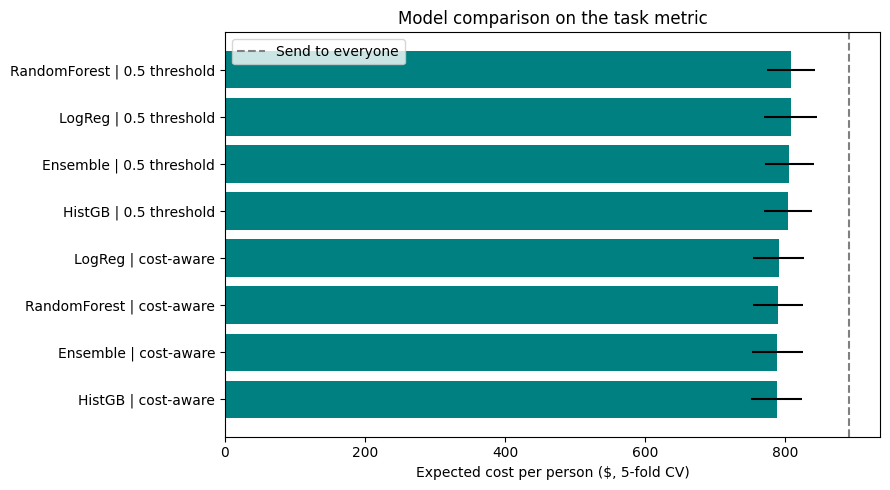

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = results["model"] + " | " + results["rule"]
ax.barh(labels, results["cost_per_person"], xerr=results["std_across_folds"], color="teal")
ax.axvline(baselines["Send to everyone"] / len(y), ls="--", color="grey", label="Send to everyone")
ax.set_xlabel("Expected cost per person ($, 5-fold CV)"); ax.set_title("Model comparison on the task metric")
ax.legend(); plt.tight_layout(); plt.show()